In [18]:
# Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.linear_model import LinearRegression

from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
# Load the Data
df = pd.read_csv('../Data/auto_mpg.csv')

In [3]:
print(df.sample(5))

     horsepower   mpg
384        96.0  32.0
169        96.0  24.0
333        72.0  32.4
152        72.0  15.0
31         95.0  25.0


# Data Cleaning

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 392 entries, 0 to 391
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   horsepower  392 non-null    float64
 1   mpg         392 non-null    float64
dtypes: float64(2)
memory usage: 6.3 KB


In [5]:
df.horsepower = df.horsepower.astype(int)

In [6]:
# Handling Missing & Duplicate Values
missing_values_count   = df.isnull().sum().sum()
duplicate_values_count = df.duplicated(subset=('horsepower','mpg')).sum()

print("Total Missing Values  :",missing_values_count)
print("Total Duplicate Values:",duplicate_values_count)

if duplicate_values_count > 0:
    df.drop_duplicates(subset=('horsepower','mpg'), inplace=True)
    print('Duplicate values removed..')

Duplicate values removed..
Total Missing Values  : 0
Total Duplicate Values: 60


In [7]:
df.sample(5)

,horsepower,mpg
307,76,41.5
20,87,25.0
184,83,27.0
187,120,15.5
310,65,37.2


# EDA

In [8]:
df.corr()

,horsepower,mpg
horsepower,1.000000,-0.772111
mpg,-0.772111,1.000000


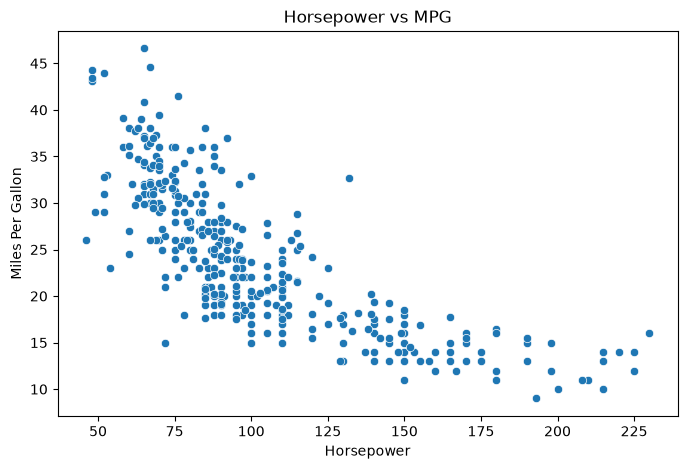

In [9]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data = df,
    x = 'horsepower',
    y = 'mpg'
)

plt.title("Horsepower vs MPG")
plt.xlabel("Horsepower")
plt.ylabel("Miles Per Gallon")

plt.show()

# Split train & test

In [10]:
x = df[['horsepower']]
y = df[['mpg']]

In [11]:
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (265, 1)
X_test: (67, 1)
y_train: (265, 1)
y_test: (67, 1)


# Pipeline

In [14]:
pipeline = Pipeline([

    ("imputer", SimpleImputer(strategy="median")),

    ("transformer", PowerTransformer(
        method="yeo-johnson",
        standardize=False
    )),

    ("scaler", StandardScaler()),

    ("model", LinearRegression())

])

# Train the model

In [15]:
pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('transformer', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['horsepower']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy o

# Make predictions

In [16]:
y_pred = pipeline.predict(X_test)

print("Actual Values:")
print(y_test.head().values)

print("\nPredicted Values:")
print(y_pred[:5])

Actual Values:
[[10. ]
 [36. ]
 [14. ]
 [19.9]
 [11. ]]

Predicted Values:
[[11.95970678]
 [28.74173803]
 [17.42964578]
 [21.14308121]
 [11.45305116]]


# Model evaluation

In [20]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 3.027499802817619
MSE: 14.092490217786974
RMSE: 3.7539965660329226
R2 Score: 0.747677654617142


# Visualize actual vs predicted values

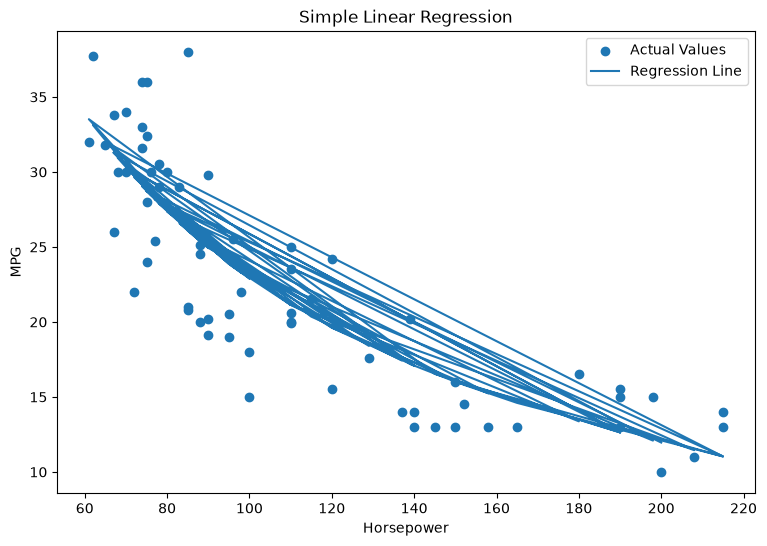

In [23]:
plt.figure(figsize=(9, 6))

# Actual data
plt.scatter(
    X_test,
    y_test,
    label="Actual Values"
)

# Regression line
plt.plot(
    X_test.values.flatten(),
    y_pred,
    label="Regression Line"
)

plt.title("Simple Linear Regression")
plt.xlabel("Horsepower")
plt.ylabel("MPG")

plt.legend()
plt.show()

# Predict for a new car

In [22]:
new_car = pd.DataFrame({
    "horsepower": [150]
})

prediction = pipeline.predict(new_car)

print("Predicted MPG:", prediction[0])

Predicted MPG: [16.01729493]
